# 14 - WLASL2000 Video Audit

## Goal

Comprehensive audit of the full WLASL2000 dataset to understand exactly what data
is available before committing to a multi-hour landmark extraction run.

## Deliverable

A clear report answering: **"Of the X videos promised in the original annotations,
Y have been downloaded successfully."**

## Data Sources

- `WLASL_v0.3.json` - Full metadata for 2000 glosses with instances
- `nslt_2000.json` - Video ID to class/split mapping (21,095 entries)
- `nslt_1000.json`, `nslt_300.json`, `nslt_100.json` - Subset annotations
- `wlasl_class_list.txt` - Class index to gloss name (2000 entries)
- `missing.txt` - Known missing video IDs
- `videos/` directory - Actual MP4 files on disk

In [1]:
import json
import numpy as np
from pathlib import Path
from collections import Counter, defaultdict
from typing import Dict, List, Set, Tuple
from datetime import datetime
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# === Paths ===
BASE = Path("/home/fransando/Dev/tfg-sign-language-recognition")
RAW_ROOT = BASE / "06_datasets" / "wlasl" / "raw"
KAGGLE_ROOT = RAW_ROOT / "kaggle_wlasl"
VIDEOS_DIR = KAGGLE_ROOT / "videos"

WLASL_V03_PATH = RAW_ROOT / "WLASL_v0.3.json"
NSLT_2000_PATH = KAGGLE_ROOT / "nslt_2000.json"
NSLT_1000_PATH = KAGGLE_ROOT / "nslt_1000.json"
NSLT_300_PATH = KAGGLE_ROOT / "nslt_300.json"
NSLT_100_PATH = KAGGLE_ROOT / "nslt_100.json"
CLASS_LIST_PATH = KAGGLE_ROOT / "wlasl_class_list.txt"
MISSING_PATH = KAGGLE_ROOT / "missing.txt"

OUTPUT_PATH = RAW_ROOT / "wlasl2000_audit.json"

print(f"Audit date: {datetime.now().strftime('%Y-%m-%d %H:%M')}")
print(f"\nPaths:")
for name, path in [
    ("WLASL_v0.3", WLASL_V03_PATH),
    ("nslt_2000", NSLT_2000_PATH),
    ("class_list", CLASS_LIST_PATH),
    ("missing", MISSING_PATH),
    ("videos", VIDEOS_DIR),
]:
    print(f"  {name}: {path.exists()}")

Audit date: 2026-02-18 11:14

Paths:
  WLASL_v0.3: True
  nslt_2000: True
  class_list: True
  missing: True
  videos: True


In [2]:
# === Load all data sources ===

# 1. WLASL_v0.3.json - rich metadata (2000 glosses with instances)
with open(WLASL_V03_PATH) as f:
    wlasl_v03 = json.load(f)
print(f"WLASL_v0.3: {len(wlasl_v03)} glosses")

# 2. nslt annotation files
nslt_data = {}
for name, path in [("100", NSLT_100_PATH), ("300", NSLT_300_PATH),
                    ("1000", NSLT_1000_PATH), ("2000", NSLT_2000_PATH)]:
    with open(path) as f:
        nslt_data[name] = json.load(f)
    print(f"nslt_{name}: {len(nslt_data[name])} entries")

# 3. Class list (index -> gloss)
class_list = {}
with open(CLASS_LIST_PATH) as f:
    for line in f:
        parts = line.strip().split('\t')
        if len(parts) == 2:
            class_list[int(parts[0])] = parts[1]
print(f"Class list: {len(class_list)} glosses")

# 4. Missing video IDs
with open(MISSING_PATH) as f:
    missing_ids = set(line.strip() for line in f if line.strip())
print(f"Missing.txt: {len(missing_ids)} video IDs")

# 5. Scan videos directory for actual files on disk
available_files = set()
for mp4 in VIDEOS_DIR.glob("*.mp4"):
    available_files.add(mp4.stem)  # video ID without .mp4
print(f"Videos on disk: {len(available_files)} MP4 files")

WLASL_v0.3: 2000 glosses
nslt_100: 2038 entries
nslt_300: 5118 entries
nslt_1000: 13174 entries
nslt_2000: 21095 entries
Class list: 2000 glosses
Missing.txt: 9103 video IDs
Videos on disk: 11980 MP4 files


---
## Basic Counts
---

In [3]:
# === Basic counts and cross-checks ===

# All video IDs referenced in nslt_2000
nslt_2000_ids = set(nslt_data["2000"].keys())

# All video IDs from WLASL_v0.3 instances
v03_ids = set()
for gloss_entry in wlasl_v03:
    for inst in gloss_entry.get("instances", []):
        v03_ids.add(str(inst["video_id"]))

# Cross-checks
on_disk_and_annotated = available_files & nslt_2000_ids
on_disk_not_annotated = available_files - nslt_2000_ids  # orphans
annotated_not_on_disk = nslt_2000_ids - available_files  # missing
annotated_in_missing = annotated_not_on_disk & missing_ids
annotated_truly_lost = annotated_not_on_disk - missing_ids  # not on disk, not in missing.txt

print("=" * 70)
print("WLASL2000 VIDEO AUDIT - BASIC COUNTS")
print("=" * 70)
print(f"")
print(f"{'Source':<35} {'Count':>8}")
print("-" * 45)
print(f"{'WLASL_v0.3 glosses':<35} {len(wlasl_v03):>8}")
print(f"{'WLASL_v0.3 total instances':<35} {len(v03_ids):>8}")
print(f"{'nslt_2000 entries':<35} {len(nslt_2000_ids):>8}")
print(f"{'missing.txt entries':<35} {len(missing_ids):>8}")
print(f"{'MP4 files on disk':<35} {len(available_files):>8}")
print(f"")
print(f"{'Cross-check':<35} {'Count':>8}")
print("-" * 45)
print(f"{'On disk AND annotated':<35} {len(on_disk_and_annotated):>8}")
print(f"{'On disk but NOT annotated':<35} {len(on_disk_not_annotated):>8}")
print(f"{'Annotated but NOT on disk':<35} {len(annotated_not_on_disk):>8}")
print(f"{'  - Listed in missing.txt':<35} {len(annotated_in_missing):>8}")
print(f"{'  - Truly lost (not in missing)':<35} {len(annotated_truly_lost):>8}")
print(f"")
coverage = len(on_disk_and_annotated) / len(nslt_2000_ids) * 100
print(f"COVERAGE: {len(on_disk_and_annotated)}/{len(nslt_2000_ids)} = {coverage:.1f}%")

WLASL2000 VIDEO AUDIT - BASIC COUNTS

Source                                 Count
---------------------------------------------
WLASL_v0.3 glosses                      2000
WLASL_v0.3 total instances             21083
nslt_2000 entries                      21095
missing.txt entries                     9103
MP4 files on disk                      11980

Cross-check                            Count
---------------------------------------------
On disk AND annotated                  11980
On disk but NOT annotated                  0
Annotated but NOT on disk               9115
  - Listed in missing.txt               9103
  - Truly lost (not in missing)           12

COVERAGE: 11980/21095 = 56.8%


---
## Per-Subset Viability
---

In [4]:
# === Per-subset viability analysis ===

def analyze_subset(nslt: Dict, available: Set[str], class_list: Dict) -> Dict:
    """Analyze a nslt subset for viability."""
    total = len(nslt)
    available_count = 0
    by_split = defaultdict(int)
    by_split_available = defaultdict(int)
    
    # Gather unique class indices
    class_indices = set()
    gloss_videos = defaultdict(lambda: {"total": 0, "available": 0, "train": 0, "val": 0, "test": 0})
    
    for vid_id, info in nslt.items():
        cls_idx = info["action"][0]
        split = info["subset"]
        gloss = class_list.get(cls_idx, f"unknown_{cls_idx}")
        class_indices.add(cls_idx)
        
        by_split[split] += 1
        gloss_videos[gloss]["total"] += 1
        
        if vid_id in available:
            available_count += 1
            by_split_available[split] += 1
            gloss_videos[gloss]["available"] += 1
            gloss_videos[gloss][split] += 1
    
    # Count glosses by minimum available videos
    avail_per_gloss = [g["available"] for g in gloss_videos.values()]
    
    return {
        "total_annotated": total,
        "available": available_count,
        "coverage_pct": available_count / total * 100 if total > 0 else 0,
        "unique_classes": len(class_indices),
        "by_split_total": dict(by_split),
        "by_split_available": dict(by_split_available),
        "glosses_with_0": sum(1 for v in avail_per_gloss if v == 0),
        "glosses_with_gte1": sum(1 for v in avail_per_gloss if v >= 1),
        "glosses_with_gte3": sum(1 for v in avail_per_gloss if v >= 3),
        "glosses_with_gte5": sum(1 for v in avail_per_gloss if v >= 5),
        "min_videos_per_gloss": min(avail_per_gloss) if avail_per_gloss else 0,
        "max_videos_per_gloss": max(avail_per_gloss) if avail_per_gloss else 0,
        "mean_videos_per_gloss": float(np.mean(avail_per_gloss)) if avail_per_gloss else 0,
        "median_videos_per_gloss": float(np.median(avail_per_gloss)) if avail_per_gloss else 0,
        "gloss_videos": {k: dict(v) for k, v in gloss_videos.items()},
    }


subset_results = {}
for name in ["100", "300", "1000", "2000"]:
    subset_results[name] = analyze_subset(nslt_data[name], available_files, class_list)

# Print viability table
print("=" * 90)
print("SUBSET VIABILITY TABLE")
print("=" * 90)
print(f"{'Subset':<10} {'Annotated':>10} {'Available':>10} {'Coverage':>10} "
      f"{'Classes':>10} {'>=1 vid':>10} {'>=3 vid':>10} {'>=5 vid':>10}")
print("-" * 90)
for name in ["100", "300", "1000", "2000"]:
    r = subset_results[name]
    print(f"WLASL{name:<5} {r['total_annotated']:>10} {r['available']:>10} "
          f"{r['coverage_pct']:>9.1f}% {r['unique_classes']:>10} "
          f"{r['glosses_with_gte1']:>10} {r['glosses_with_gte3']:>10} "
          f"{r['glosses_with_gte5']:>10}")

print(f"\n--- Train/Val/Test splits (available videos) ---")
print(f"{'Subset':<10} {'Train':>10} {'Val':>10} {'Test':>10}")
print("-" * 45)
for name in ["100", "300", "1000", "2000"]:
    r = subset_results[name]
    s = r["by_split_available"]
    print(f"WLASL{name:<5} {s.get('train', 0):>10} {s.get('val', 0):>10} {s.get('test', 0):>10}")

SUBSET VIABILITY TABLE
Subset      Annotated  Available   Coverage    Classes    >=1 vid    >=3 vid    >=5 vid
------------------------------------------------------------------------------------------
WLASL100         2038       1013      49.7%        100        100        100        100
WLASL300         5118       2660      52.0%        300        300        300        300
WLASL1000       13174       7232      54.9%       1000       1000        999        979
WLASL2000       21095      11980      56.8%       2000       2000       1986       1575

--- Train/Val/Test splits (available videos) ---
Subset          Train        Val       Test
---------------------------------------------
WLASL100          748        165        100
WLASL300         1897        446        317
WLASL1000        5001       1290        941
WLASL2000        8313       2253       1414


---
## Per-Gloss Analysis (WLASL2000)
---

In [5]:
# === Per-gloss distribution for WLASL2000 ===

gloss_info = subset_results["2000"]["gloss_videos"]
avail_counts = sorted([g["available"] for g in gloss_info.values()], reverse=True)

print("=" * 60)
print("WLASL2000 - VIDEOS PER GLOSS DISTRIBUTION")
print("=" * 60)
print(f"Total glosses: {len(gloss_info)}")
print(f"Min available videos/gloss: {min(avail_counts)}")
print(f"Max available videos/gloss: {max(avail_counts)}")
print(f"Mean: {np.mean(avail_counts):.1f}")
print(f"Median: {np.median(avail_counts):.1f}")
print(f"Std: {np.std(avail_counts):.1f}")
print(f"")
print(f"Glosses with 0 videos: {sum(1 for c in avail_counts if c == 0)}")
print(f"Glosses with 1 video:  {sum(1 for c in avail_counts if c == 1)}")
print(f"Glosses with 2 videos: {sum(1 for c in avail_counts if c == 2)}")
print(f"Glosses with 3-5:      {sum(1 for c in avail_counts if 3 <= c <= 5)}")
print(f"Glosses with 6-10:     {sum(1 for c in avail_counts if 6 <= c <= 10)}")
print(f"Glosses with 11-20:    {sum(1 for c in avail_counts if 11 <= c <= 20)}")
print(f"Glosses with 20+:      {sum(1 for c in avail_counts if c > 20)}")

WLASL2000 - VIDEOS PER GLOSS DISTRIBUTION
Total glosses: 2000
Min available videos/gloss: 2
Max available videos/gloss: 16
Mean: 6.0
Median: 6.0
Std: 1.9

Glosses with 0 videos: 0
Glosses with 1 video:  0
Glosses with 2 videos: 14
Glosses with 3-5:      922
Glosses with 6-10:     1008
Glosses with 11-20:    56
Glosses with 20+:      0


In [6]:
# === Problem glosses: those with very few videos ===

print("=" * 60)
print("PROBLEM GLOSSES (fewer than 3 available videos)")
print("=" * 60)

problem_glosses = sorted(
    [(gloss, info["available"], info["total"]) 
     for gloss, info in gloss_info.items() if info["available"] < 3],
    key=lambda x: x[1]
)

print(f"\n{len(problem_glosses)} glosses with < 3 available videos:")
print(f"\n{'Gloss':<25} {'Available':>10} {'Annotated':>10} {'Loss':>10}")
print("-" * 58)
for gloss, avail, total in problem_glosses[:40]:  # Show top 40
    print(f"{gloss:<25} {avail:>10} {total:>10} {total - avail:>10}")
if len(problem_glosses) > 40:
    print(f"  ... and {len(problem_glosses) - 40} more")

PROBLEM GLOSSES (fewer than 3 available videos)

14 glosses with < 3 available videos:

Gloss                      Available  Annotated       Loss
----------------------------------------------------------
post                               2          7          5
grey                               2          7          5
gloves                             2         10          8
look at                            2          7          5
stepfather                         2          7          5
lamp                               2          7          5
tv                                 2          7          5
propaganda                         2          7          5
careless                           2          8          6
meaning                            2          7          5
smoking                            2          7          5
ski                                2          7          5
wash face                          2          8          6
curtain                    

In [7]:
# === Top glosses: those with most videos ===

print("=" * 60)
print("TOP 30 GLOSSES (most available videos)")
print("=" * 60)

top_glosses = sorted(
    [(gloss, info["available"], info["train"], info["val"], info["test"])
     for gloss, info in gloss_info.items()],
    key=lambda x: x[1], reverse=True
)

print(f"\n{'Gloss':<25} {'Available':>10} {'Train':>8} {'Val':>6} {'Test':>6}")
print("-" * 58)
for gloss, avail, train, val, test in top_glosses[:30]:
    print(f"{gloss:<25} {avail:>10} {train:>8} {val:>6} {test:>6}")

TOP 30 GLOSSES (most available videos)

Gloss                      Available    Train    Val   Test
----------------------------------------------------------
before                            16       12      1      3
thin                              16       11      3      2
cool                              16       11      3      2
drink                             15       11      3      1
go                                15       11      3      1
help                              14       10      2      2
who                               14       10      3      1
cousin                            14        9      3      2
computer                          14       10      3      1
tall                              13       10      2      1
thanksgiving                      13        9      3      1
trade                             13       10      2      1
candy                             13        8      2      3
bed                               13       12      1      0
a

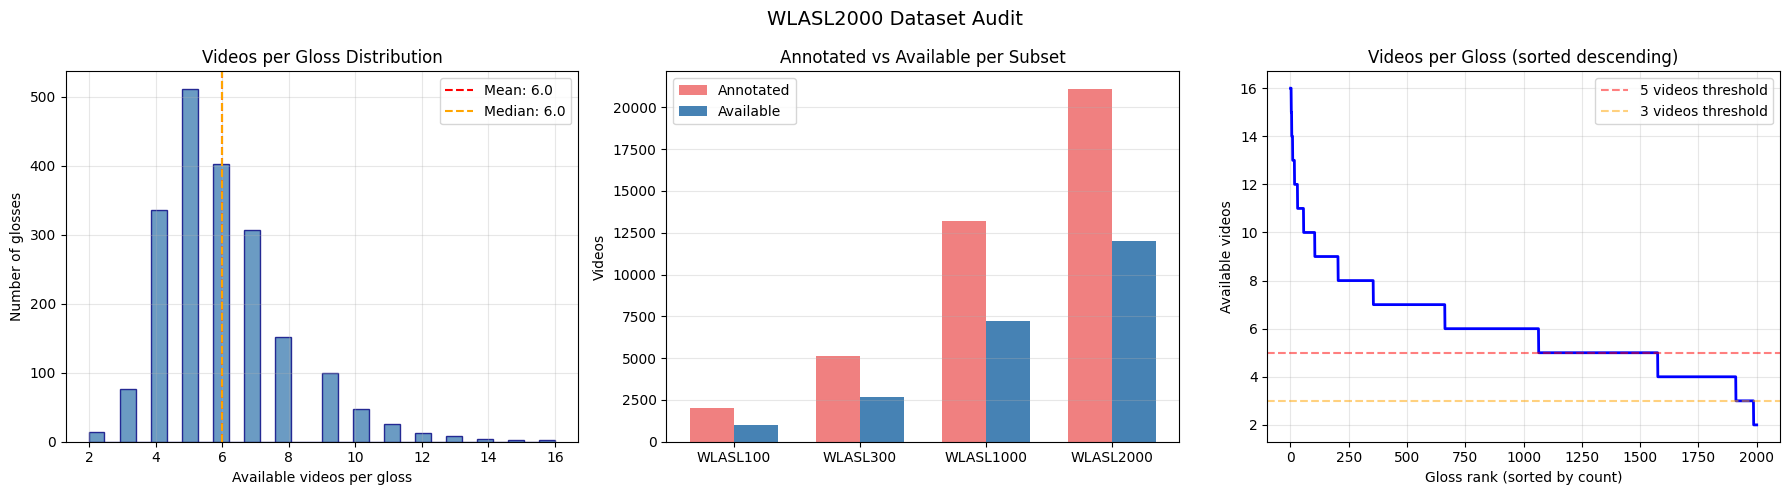

In [8]:
# === Visualizations ===

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Histogram of videos per gloss
axes[0].hist(avail_counts, bins=30, color='steelblue', edgecolor='navy', alpha=0.8)
axes[0].axvline(np.mean(avail_counts), color='red', linestyle='--',
                label=f'Mean: {np.mean(avail_counts):.1f}')
axes[0].axvline(np.median(avail_counts), color='orange', linestyle='--',
                label=f'Median: {np.median(avail_counts):.1f}')
axes[0].set_xlabel('Available videos per gloss')
axes[0].set_ylabel('Number of glosses')
axes[0].set_title('Videos per Gloss Distribution')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# 2. Subset viability bar chart
subset_names = ['WLASL100', 'WLASL300', 'WLASL1000', 'WLASL2000']
annotated = [subset_results[n]["total_annotated"] for n in ["100", "300", "1000", "2000"]]
available = [subset_results[n]["available"] for n in ["100", "300", "1000", "2000"]]

x = np.arange(len(subset_names))
w = 0.35
axes[1].bar(x - w/2, annotated, w, label='Annotated', color='lightcoral')
axes[1].bar(x + w/2, available, w, label='Available', color='steelblue')
axes[1].set_xticks(x)
axes[1].set_xticklabels(subset_names)
axes[1].set_ylabel('Videos')
axes[1].set_title('Annotated vs Available per Subset')
axes[1].legend()
axes[1].grid(True, alpha=0.3, axis='y')

# 3. Cumulative gloss coverage
sorted_counts = sorted(avail_counts, reverse=True)
axes[2].plot(range(1, len(sorted_counts) + 1), sorted_counts, 'b-', linewidth=2)
axes[2].axhline(5, color='red', linestyle='--', alpha=0.5, label='5 videos threshold')
axes[2].axhline(3, color='orange', linestyle='--', alpha=0.5, label='3 videos threshold')
axes[2].set_xlabel('Gloss rank (sorted by count)')
axes[2].set_ylabel('Available videos')
axes[2].set_title('Videos per Gloss (sorted descending)')
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.suptitle('WLASL2000 Dataset Audit', fontsize=14)
plt.tight_layout()
plt.savefig(str(RAW_ROOT / 'wlasl2000_audit_charts.png'), dpi=150, bbox_inches='tight')
plt.show()

In [9]:
# === Save comprehensive audit report ===

audit_report = {
    "audit_date": datetime.now().strftime("%Y-%m-%d %H:%M"),
    "sources": {
        "wlasl_v03": {
            "total_glosses": len(wlasl_v03),
            "total_instances": len(v03_ids),
        },
        "nslt_2000": {
            "total_entries": len(nslt_2000_ids),
        },
        "missing_txt": len(missing_ids),
    },
    "available_videos": {
        "on_disk": len(available_files),
        "on_disk_and_annotated": len(on_disk_and_annotated),
        "on_disk_not_annotated": len(on_disk_not_annotated),
        "annotated_not_on_disk": len(annotated_not_on_disk),
        "in_missing_txt": len(annotated_in_missing),
        "truly_lost": len(annotated_truly_lost),
        "coverage_pct": coverage,
    },
    "per_subset": {},
    "gloss_distribution": {
        "total_glosses": len(gloss_info),
        "min_videos_per_gloss": int(min(avail_counts)),
        "max_videos_per_gloss": int(max(avail_counts)),
        "mean_videos_per_gloss": float(np.mean(avail_counts)),
        "median_videos_per_gloss": float(np.median(avail_counts)),
        "glosses_with_0_videos": sum(1 for c in avail_counts if c == 0),
        "glosses_with_fewer_than_3": sum(1 for c in avail_counts if c < 3),
        "glosses_with_fewer_than_5": sum(1 for c in avail_counts if c < 5),
    },
}

# Add per-subset stats (without the large gloss_videos dict)
for name in ["100", "300", "1000", "2000"]:
    r = subset_results[name].copy()
    r.pop("gloss_videos", None)  # Remove large dict from JSON
    audit_report["per_subset"][f"wlasl{name}"] = r

with open(OUTPUT_PATH, 'w') as f:
    json.dump(audit_report, f, indent=2, ensure_ascii=False)

print(f"Audit report saved to: {OUTPUT_PATH}")
print(f"Charts saved to: {RAW_ROOT / 'wlasl2000_audit_charts.png'}")

Audit report saved to: /home/fransando/Dev/tfg-sign-language-recognition/06_datasets/wlasl/raw/wlasl2000_audit.json
Charts saved to: /home/fransando/Dev/tfg-sign-language-recognition/06_datasets/wlasl/raw/wlasl2000_audit_charts.png


In [10]:
# === Final Summary ===

print("\n" + "=" * 70)
print("FINAL AUDIT SUMMARY")
print("=" * 70)
print(f"")
print(f"Of the {len(nslt_2000_ids):,} videos annotated in WLASL2000:")
print(f"  - {len(on_disk_and_annotated):,} downloaded successfully ({coverage:.1f}%)")
print(f"  - {len(annotated_not_on_disk):,} are missing")
print(f"")
print(f"Total MP4 files on disk: {len(available_files):,}")
print(f"Total usable (annotated + on disk): {len(on_disk_and_annotated):,}")
print(f"")
print("Viable subsets for training:")
for name in ["100", "300", "1000", "2000"]:
    r = subset_results[name]
    print(f"  WLASL{name:>4}: {r['available']:>6} videos / "
          f"{r['glosses_with_gte1']:>5} glosses with >=1 vid / "
          f"{r['glosses_with_gte3']:>5} with >=3 / "
          f"{r['glosses_with_gte5']:>5} with >=5")

print(f"\n--- Recommended progression ---")
for name in ["100", "300", "1000", "2000"]:
    r = subset_results[name]
    s = r["by_split_available"]
    print(f"  WLASL{name:>4}: train={s.get('train', 0)}, "
          f"val={s.get('val', 0)}, test={s.get('test', 0)} "
          f"(mean {r['mean_videos_per_gloss']:.1f} vid/gloss)")

print(f"\n{'=' * 70}")
print("READY FOR NOTEBOOK 15: Full Landmark Extraction")
print(f"{'=' * 70}")


FINAL AUDIT SUMMARY

Of the 21,095 videos annotated in WLASL2000:
  - 11,980 downloaded successfully (56.8%)
  - 9,115 are missing

Total MP4 files on disk: 11,980
Total usable (annotated + on disk): 11,980

Viable subsets for training:
  WLASL 100:   1013 videos /   100 glosses with >=1 vid /   100 with >=3 /   100 with >=5
  WLASL 300:   2660 videos /   300 glosses with >=1 vid /   300 with >=3 /   300 with >=5
  WLASL1000:   7232 videos /  1000 glosses with >=1 vid /   999 with >=3 /   979 with >=5
  WLASL2000:  11980 videos /  2000 glosses with >=1 vid /  1986 with >=3 /  1575 with >=5

--- Recommended progression ---
  WLASL 100: train=748, val=165, test=100 (mean 10.1 vid/gloss)
  WLASL 300: train=1897, val=446, test=317 (mean 8.9 vid/gloss)
  WLASL1000: train=5001, val=1290, test=941 (mean 7.2 vid/gloss)
  WLASL2000: train=8313, val=2253, test=1414 (mean 6.0 vid/gloss)

READY FOR NOTEBOOK 15: Full Landmark Extraction
